# Decision Trees

## The Data

We zullen dezelfde dataset gebruiken tijdens onze discussies over classificatie met tree methods (Decision Trees, Random Forests en Gradient Boosted Trees) om de prestatie-indicatoren over deze verwante modellen te vergelijken.

We zullen werken met de "Palmer Penguins" dataset, omdat deze eenvoudig genoeg is om ons volledig te laten begrijpen hoe het veranderen van hyperparameters de classificatieresultaten kan veranderen.

<img src="penguin.jpg" style="max-width:400px">

Samenvatting:
De gegevensmap bevat twee CSV-bestanden. Voor introductiecursussen/voorbeelden wilt u waarschijnlijk het eerste bestand gebruiken (penguins_size.csv).

* penguins_size.csv: Vereenvoudigde gegevens uit originele pinguïngegevenssets. Bevat variabelen:

    * species: pinguinsoort (Chinstrap, Adélie, or Gentoo)
    * culmen_length_mm: lengte van de culmen (mm)
    * culmen_depth_mm: diepte van de culmen (mm)
    * flipper_length_mm: lengte van de flipper (mm)
    * body_mass_g: lichaamsgewicht  (g)
    * island: eilandnaam (Dream, Torgersen of Biscoe) in de Palmerarchipel (Antarctica)
    * sex: geslacht van de pinguïn

* (Niet gebruikt) penguins_lter.csv: Originele gecombineerde gegevens voor 3 pinguïnsoorten

Opmerking: De culmen is "de bovenste rand van de snavel van een vogel"

**Ons doel is om een model te creëren dat kan helpen bij het voorspellen van de soort van een pinguïn op basis van fysieke kenmerken, zodat we dat model kunnen gebruiken om onderzoekers te helpen bij het classificeren van pinguïns in het veld, in plaats van dat er een ervaren bioloog nodig is**

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df = pd.read_csv("../../DATA/penguins_size.csv")

In [25]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [26]:
df['species'].unique()   # 3 soorten

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

## Verkennende data analyse

### Ontbrekende gegevens

Herinner dat het doel is om een model voor toekomstig gebruik te creëren, dus gegevenspunten die cruciale informatie missen zullen niet helpen bij deze taak, vooral omdat we voor toekomstige gegevenspunten zullen aannemen dat het onderzoek de relevante kenmerkinformatie zal verzamelen.

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [28]:
df.isna().sum() # hoeveel ontbrekende waarden hebben we?

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

In [29]:
# Welk percentage droppen we?
100*(10/344)

2.9069767441860463

In [30]:
df = df.dropna()  # we wissen de rijen met lege waarden

In [31]:
df.info()  # we hebben 344 voorbeelden

<class 'pandas.core.frame.DataFrame'>
Int64Index: 334 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            334 non-null    object 
 1   island             334 non-null    object 
 2   culmen_length_mm   334 non-null    float64
 3   culmen_depth_mm    334 non-null    float64
 4   flipper_length_mm  334 non-null    float64
 5   body_mass_g        334 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.9+ KB


In [32]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


In [33]:
# Checken van de categorische variabelen

In [35]:
df['sex'].unique()

array(['MALE', 'FEMALE', '.'], dtype=object)

Hoe kunnen we dit opvangen?  We hebben alle andere features.  Misschien kunnen we de pinguin toekennen aan een geslacht op basis van zijn gewicht...

In [43]:
df[df['species']=='Gentoo'].groupby('sex').describe().transpose()

sex                           .       FEMALE         MALE
culmen_length_mm  count     1.0    58.000000    61.000000
                  mean     44.5    45.563793    49.473770
                  std       NaN     2.051247     2.720594
                  min      44.5    40.900000    44.400000
                  25%      44.5    43.850000    48.100000
                  50%      44.5    45.500000    49.500000
                  75%      44.5    46.875000    50.500000
                  max      44.5    50.500000    59.600000
culmen_depth_mm   count     1.0    58.000000    61.000000
                  mean     15.7    14.237931    15.718033
                  std       NaN     0.540249     0.741060
                  min      15.7    13.100000    14.100000
                  25%      15.7    13.800000    15.200000
                  50%      15.7    14.250000    15.700000
                  75%      15.7    14.600000    16.100000
                  max      15.7    15.500000    17.300000
flipper_length_mm count     1.0    58.000000    61.000000
                  mean    217.0   212.706897   221.540984
                  std       NaN     3.897856     5.673252
                  min     217.0   203.000000   208.000000
                  25%     217.0   210.000000   218.000000
                  50%     217.0   212.000000   221.000000
                  75%     217.0   215.000000   225.000000
                  max     217.0   222.000000   231.000000
body_mass_g       count     1.0    58.000000    61.000000
                  mean   4875.0  4679.741379  5484.836066
                  std       NaN   281.578294   313.158596
                  min    4875.0  3950.000000  4750.000000
                  25%    4875.0  4462.500000  5300.000000
                  50%    4875.0  4700.000000  5500.000000
                  75%    4875.0  4875.000000  5700.000000
                  max    4875.0  5200.000000  6300.000000

In [45]:
# leunt dicht aan bij een vrouwtje, vooral inzake gewicht...
df.at[336, 'sex'] = 'FEMALE'

In [48]:
# alternatief: 
# df = df[df['sex']!='.']

In [49]:
df['island'].unique()

array(['Torgersen', 'Biscoe', 'Dream'], dtype=object)

In [50]:
df.shape

(334, 7)

## Visualisatie

<Axes: xlabel='culmen_length_mm', ylabel='culmen_depth_mm'>

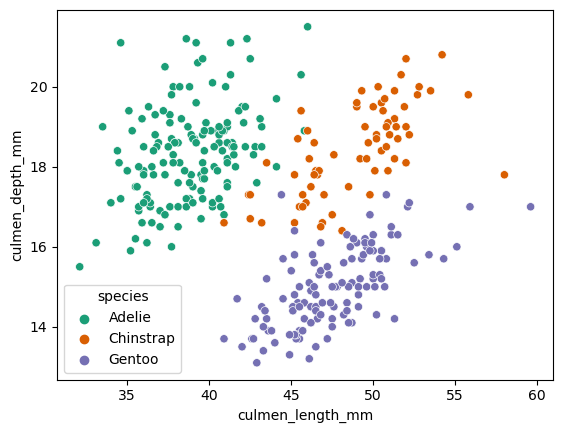

In [51]:
sns.scatterplot(x='culmen_length_mm',y='culmen_depth_mm',data=df,hue='species',palette='Dark2')

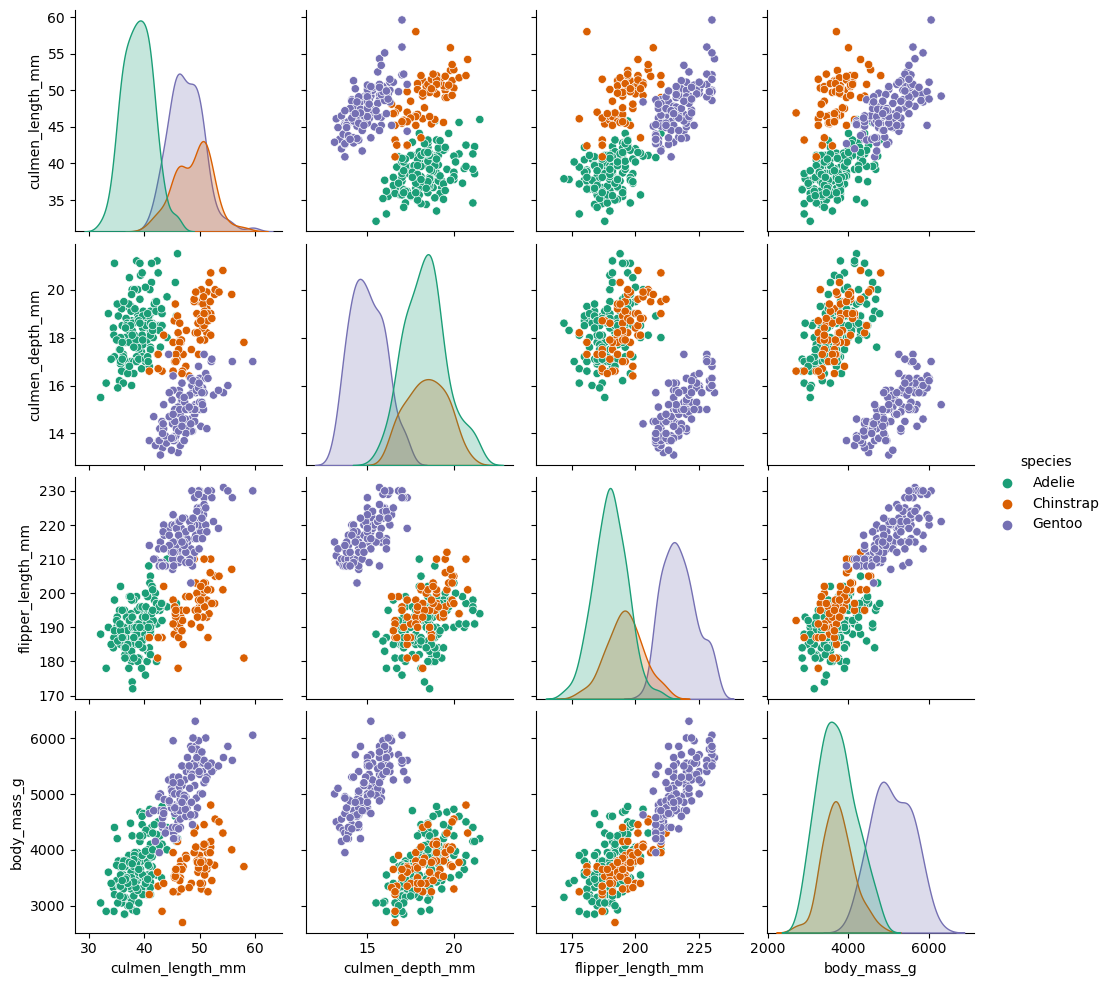

In [52]:
sns.pairplot(df,hue='species',palette='Dark2')

Er is wat overlap in de data, maar algemeen ziet het er naar uit dat een ML algoritme deze data goed moet kunnen scheiden.

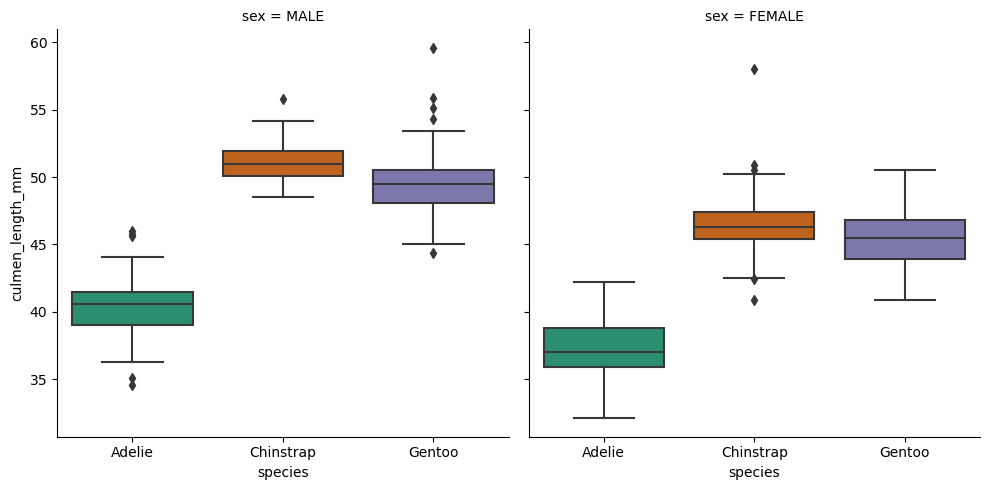

In [55]:
# categorical plot - type 'boxplot' maar je kan vb ook aangeven op welke kolom je wil filteren
sns.catplot(x='species',y='culmen_length_mm',data=df,kind='box',col='sex',palette='Dark2')

## Feature Engineering

We gaan nu de data voorbereiden voor de decision tree.  We hebben gezien dat een decision tree in theorie in staat moet zijn om met multi-categorical data te werken.  Voorbeeld: er waren meerdere eilanden.  Daarom maken we dummies.

In [56]:
# pd.get_dummies(df)

In [59]:
pd.get_dummies(df.drop('species',axis=1),drop_first=True)  
# drop_first is om de eerste waarde te droppen, 
# omdat dit geen meerwaarde heeft: vb sex_MALE geeft 0 en 1...  

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE
0,39.1,18.7,181.0,3750.0,0,1,1
1,39.5,17.4,186.0,3800.0,0,1,0
2,40.3,18.0,195.0,3250.0,0,1,0
4,36.7,19.3,193.0,3450.0,0,1,0
5,39.3,20.6,190.0,3650.0,0,1,1
...,...,...,...,...,...,...,...
338,47.2,13.7,214.0,4925.0,0,0,0
340,46.8,14.3,215.0,4850.0,0,0,0
341,50.4,15.7,222.0,5750.0,0,0,1
342,45.2,14.8,212.0,5200.0,0,0,0


Wat gebeurt er in een Beslissingsboom node?  De dataset wordt bekeken ahv één feature vb is deze feature meer of minder dan deze waarde... Daarom moeten we geen feature scaling doen: we vergelijken nooit meerdere features met elkaar...

## Train | Test Split

In [60]:
X = pd.get_dummies(df.drop('species',axis=1),drop_first=True)
y = df['species']

In [61]:
from sklearn.model_selection import train_test_split

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

# Decision Tree Classifier

## Default Hyperparameters

In [63]:
from sklearn.tree import DecisionTreeClassifier

In [66]:
# we starten met alle default parameters
model = DecisionTreeClassifier()

In [67]:
model.fit(X_train,y_train)

DecisionTreeClassifier()

In [68]:
base_pred = model.predict(X_test)

## Evaluatie

In [70]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report, ConfusionMatrixDisplay

In [71]:
confusion_matrix(y_test,base_pred)

array([[40,  1,  0],
       [ 2, 21,  0],
       [ 0,  0, 37]])

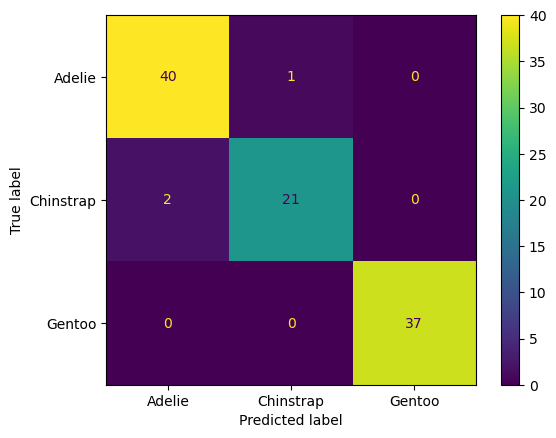

In [78]:
# Idem: confusion matrix, maar mooi geplot - Ruwe waarden
cm = confusion_matrix(y_test, base_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=model.classes_)
disp.plot()

In [79]:
print(classification_report(y_test,base_pred))

              precision    recall  f1-score   support

      Adelie       0.95      0.98      0.96        41
   Chinstrap       0.95      0.91      0.93        23
      Gentoo       1.00      1.00      1.00        37

    accuracy                           0.97       101
   macro avg       0.97      0.96      0.97       101
weighted avg       0.97      0.97      0.97       101



In [82]:
# één van de belangrijkste voordelen is de interpreteerbaarheid.  Je kan het belang van elke feature opvragen:
model.feature_importances_

array([0.33437342, 0.05366774, 0.53120101, 0.00239775, 0.07836008,
       0.        , 0.        ])

In [84]:
pd.DataFrame(index=X.columns,data=model.feature_importances_,columns=['Feature Importance']).sort_values('Feature Importance')

,Feature Importance
island_Torgersen,0.000000
sex_MALE,0.000000
body_mass_g,0.002398
culmen_depth_mm,0.053668
island_Dream,0.078360
culmen_length_mm,0.334373
flipper_length_mm,0.531201


Vaak worden niet alle features gebruikt!

<Axes: xlabel='species', ylabel='body_mass_g'>

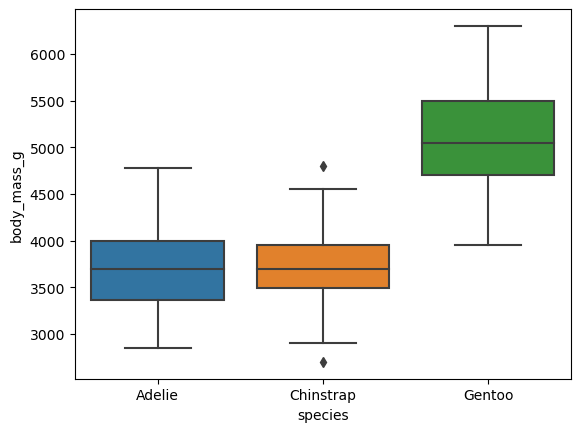

In [85]:
sns.boxplot(x='species',y='body_mass_g',data=df)

## Visualisatie van de boom

Online Documentatie: https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html

In [87]:
from sklearn.tree import plot_tree

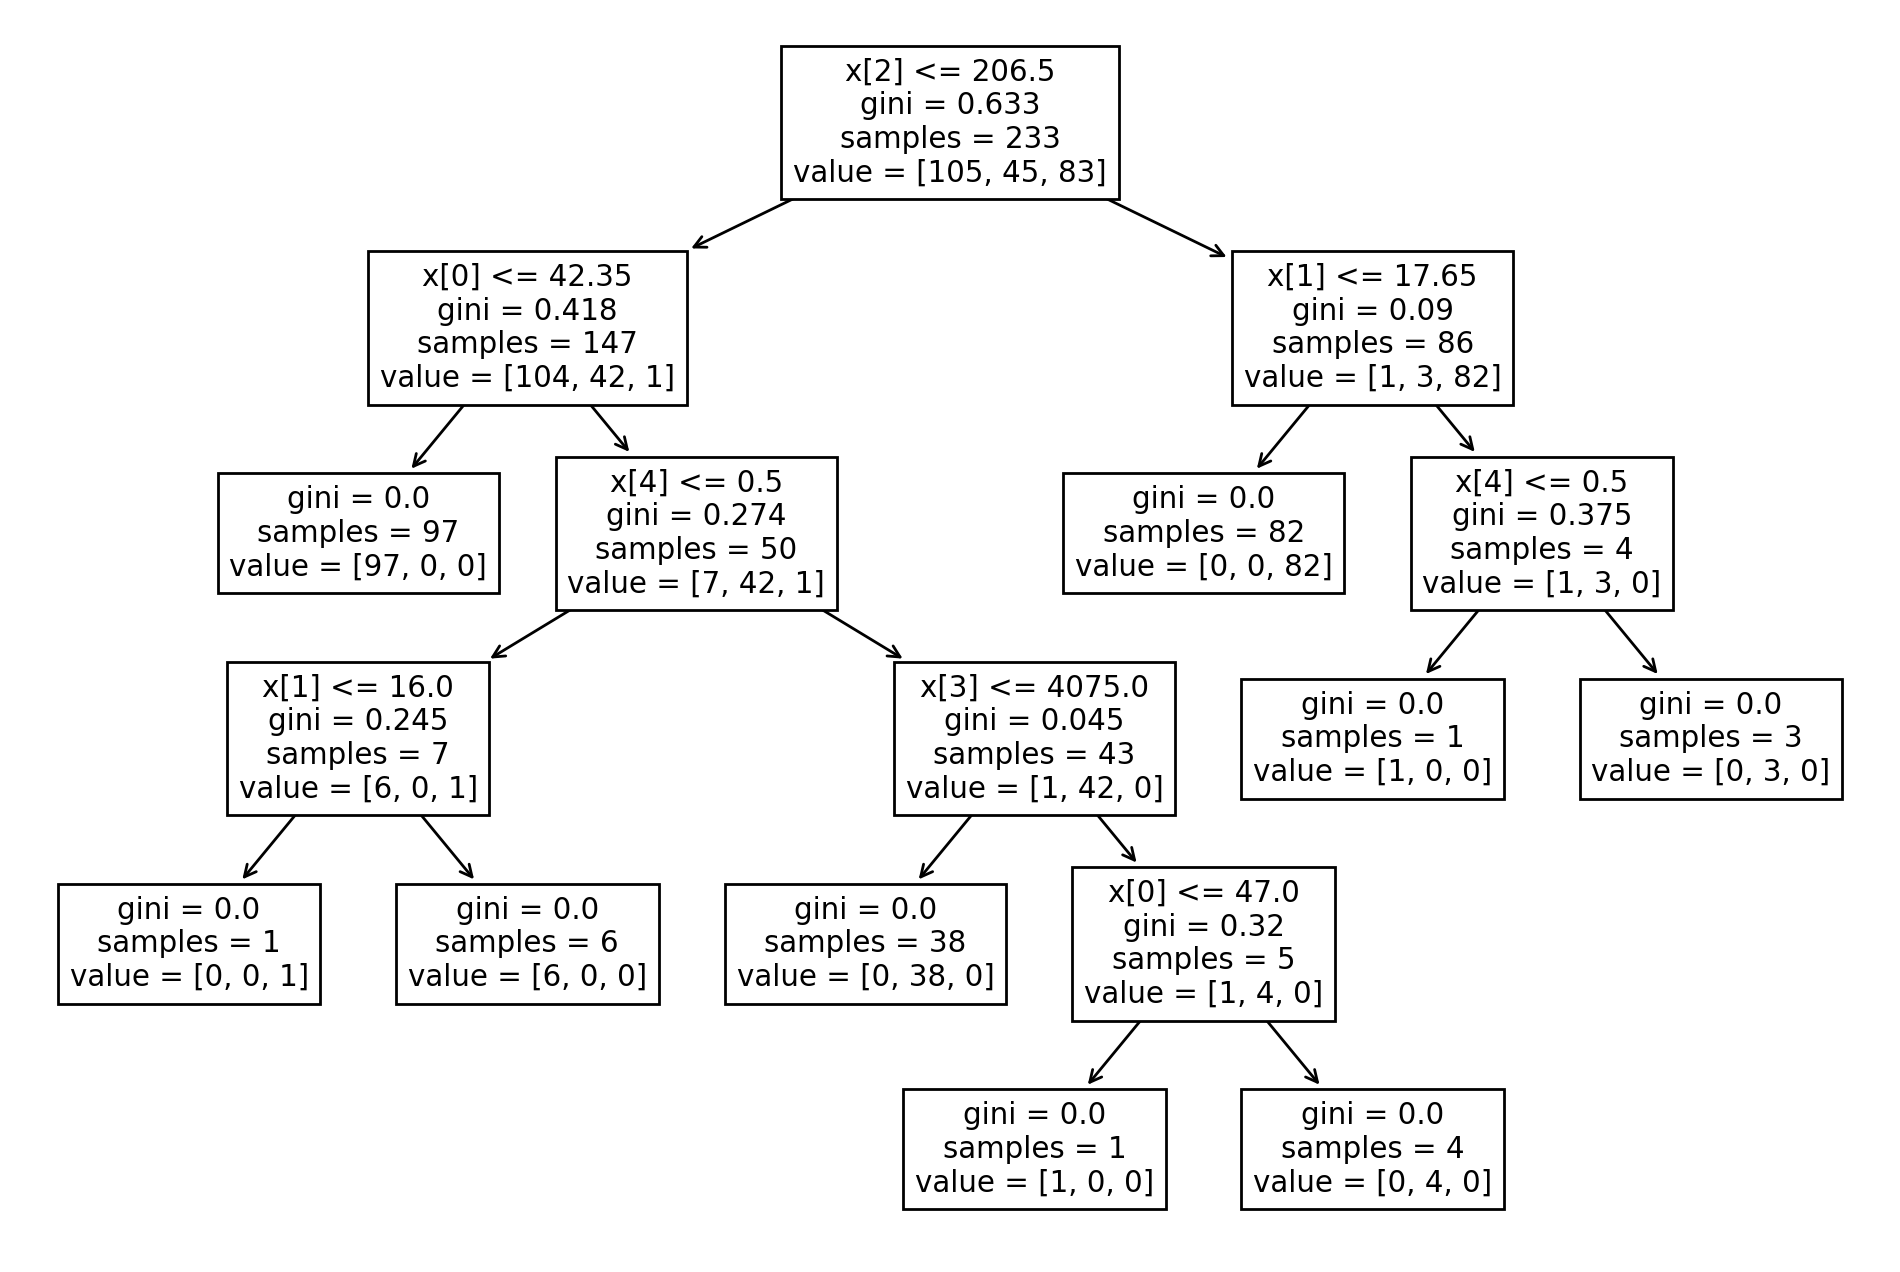

In [88]:
plt.figure(figsize=(12,8), dpi=200)
plot_tree(model);

Wat vertegenwoordigen de waarden in deze decision tree? Vb X[2] <= 206,5 betekent kolom op index 2 dus de derde kolom: de flipper length...  Dit was ook de belangrijkste feature!  Je zie ook samples =233: dit is het aantal samples die door deze node passeren; dit is de lengte van X_train.  Dan hebben we een value array = [105, 45, 83].  Deze geeft weer hoeveel er van elke klasse (soort) zijn: 105 + 45 + 83 = 233 !

Als je een leaf node hebt die vb [0,0,82] heeft, dan is deze leaf perfect geklassificeerd en dus zuiver.

We kunnen de namen ook meegeven met feature_names en filled=True voor kleuren.

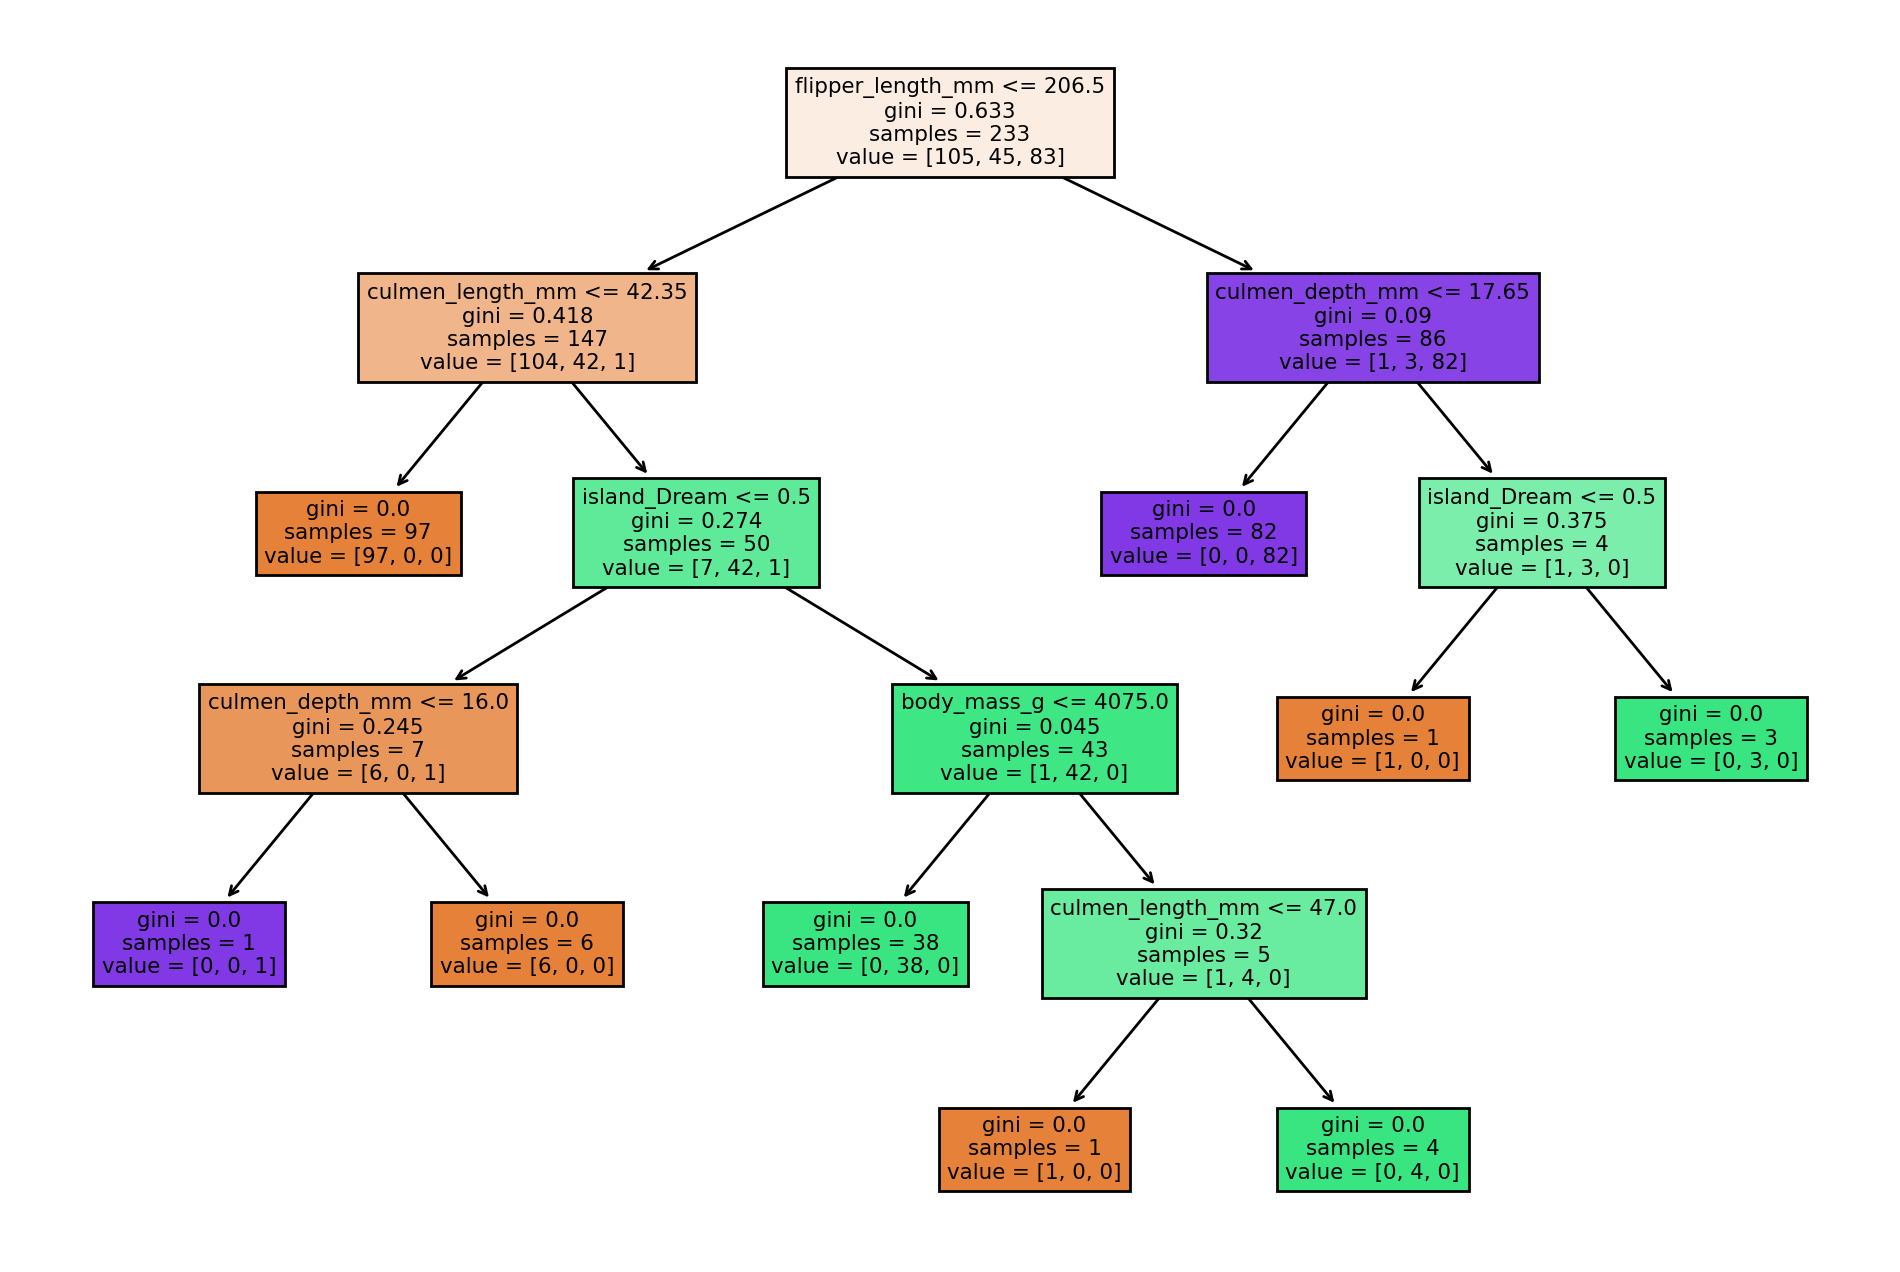

In [92]:
plt.figure(figsize=(12,8),dpi=200)
plot_tree(model,filled=True,feature_names=X.columns);

## Rapporteren van de Resultaten van het Model

Om te beginnen experimenteren met hyperparameters, gaan we een functie creëren die classificatieresultaten rapporteert en de boom weergeeft.

In [91]:
def report_model(model):
    model_preds = model.predict(X_test)
    print(classification_report(y_test,model_preds))
    print('\n')
    plt.figure(figsize=(12,8),dpi=150)
    plot_tree(model,filled=True,feature_names=X.columns);

## Begrijpen van de Hyperparameters

### Max Depth

In [93]:
# help(DecisionTreeClassifier)

In [98]:
# max_depth: hoeveel levels mag de tree splitsen? We komen van 5 levels!
pruned_tree = DecisionTreeClassifier(max_depth=2)
pruned_tree.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=2)

              precision    recall  f1-score   support

      Adelie       0.97      0.88      0.92        41
   Chinstrap       0.81      0.96      0.88        23
      Gentoo       1.00      1.00      1.00        37

    accuracy                           0.94       101
   macro avg       0.93      0.94      0.93       101
weighted avg       0.95      0.94      0.94       101





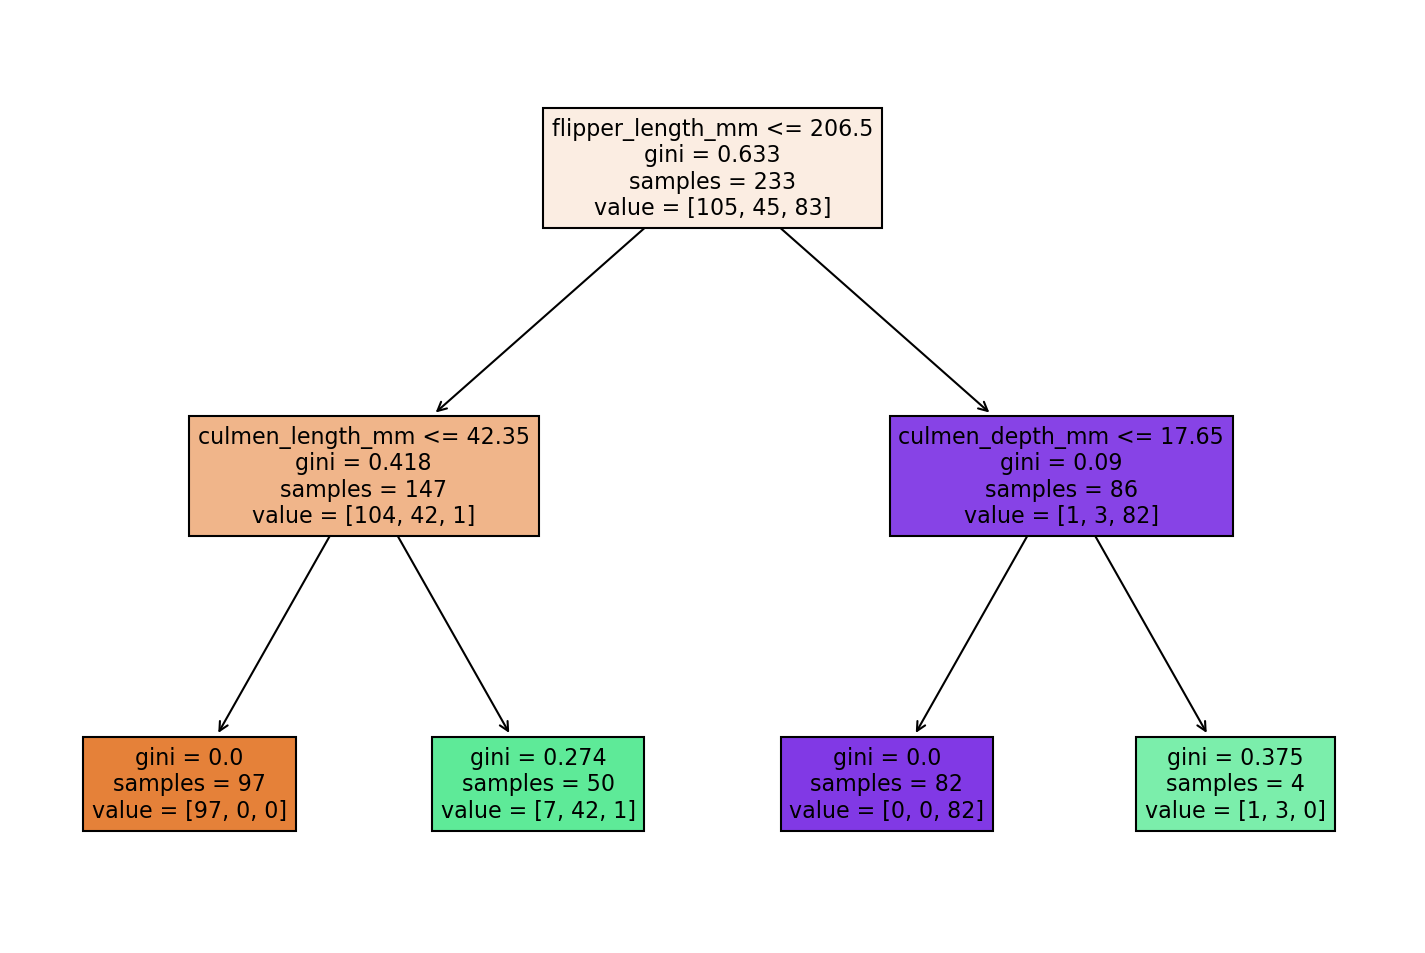

In [97]:
report_model(pruned_tree)

Er worden slechts 3 features gebruikt; de tree is veel eenvoudiger - maar we hebben daartegenover een iets minder nauwkeurig model.

## Max Leaf Nodes

In [101]:
pruned_tree = DecisionTreeClassifier(max_leaf_nodes=3)
pruned_tree.fit(X_train,y_train)

DecisionTreeClassifier(max_leaf_nodes=3)

              precision    recall  f1-score   support

      Adelie       0.97      0.88      0.92        41
   Chinstrap       0.83      0.87      0.85        23
      Gentoo       0.93      1.00      0.96        37

    accuracy                           0.92       101
   macro avg       0.91      0.92      0.91       101
weighted avg       0.92      0.92      0.92       101





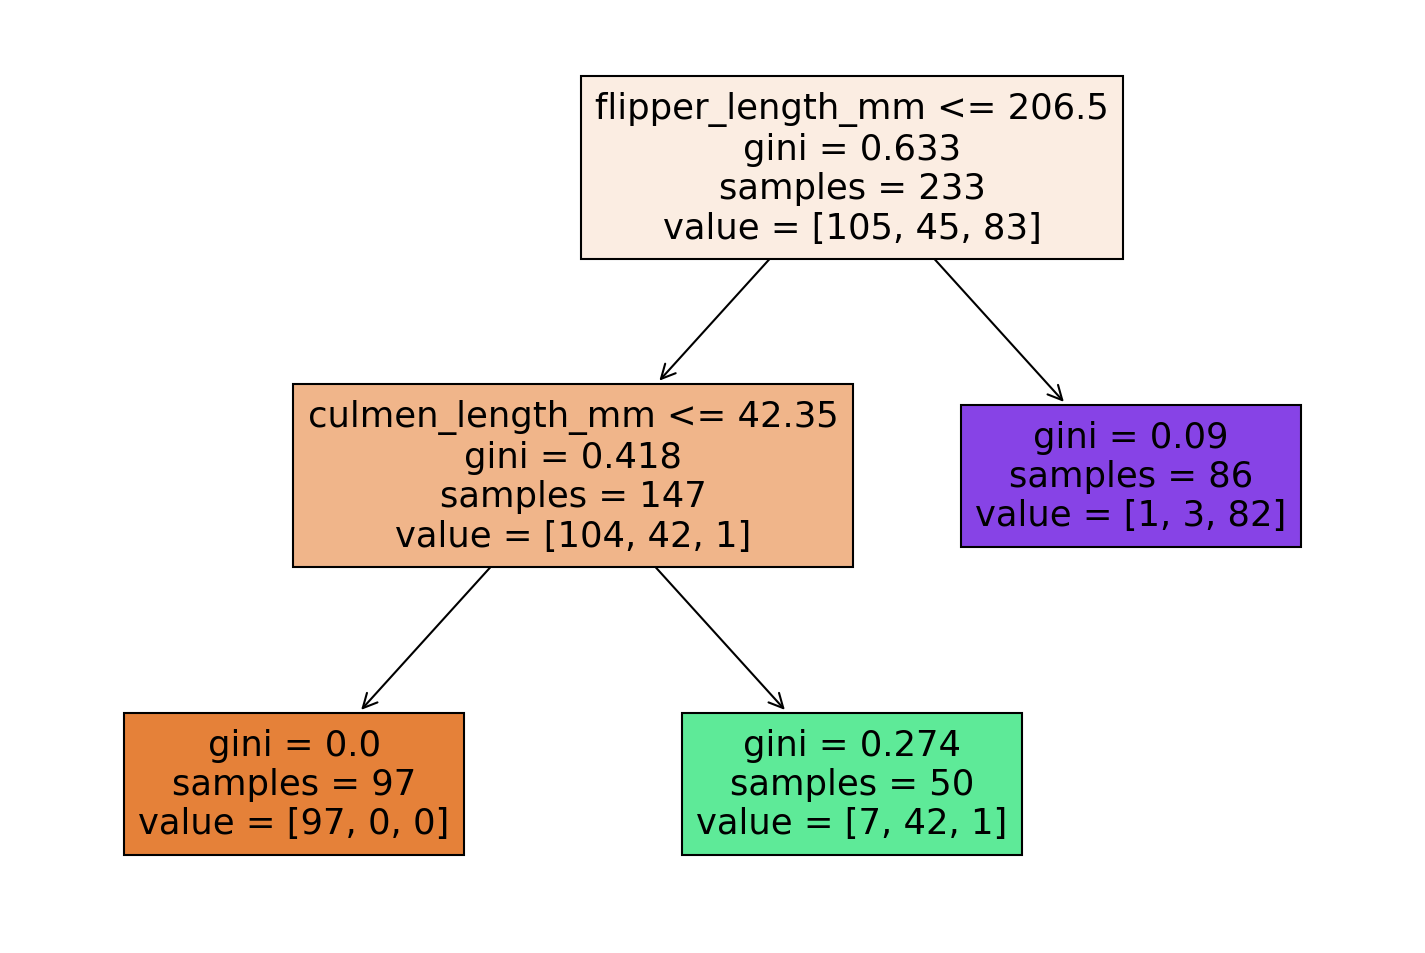

In [102]:
report_model(pruned_tree)

Zeer eenvoudige tree; redelijk goede performantie! Slechts 2 features worden gebruikt en 3 leafs terwijl we ook 3 klassen hebben!

## Criteria

In [103]:
# entropy = information_gain in plaats van gini!  Deze tree wijkt af van deze met gini, 
# maar heeft ook zeer goede resultaten. Het is gewoon een ander criterium om op te splitsen
# ipv gini, maar we gaan hier verder niet op in.
entropy_tree = DecisionTreeClassifier(criterion='entropy')
entropy_tree.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy')

              precision    recall  f1-score   support

      Adelie       0.95      0.98      0.96        41
   Chinstrap       0.95      0.91      0.93        23
      Gentoo       1.00      1.00      1.00        37

    accuracy                           0.97       101
   macro avg       0.97      0.96      0.97       101
weighted avg       0.97      0.97      0.97       101





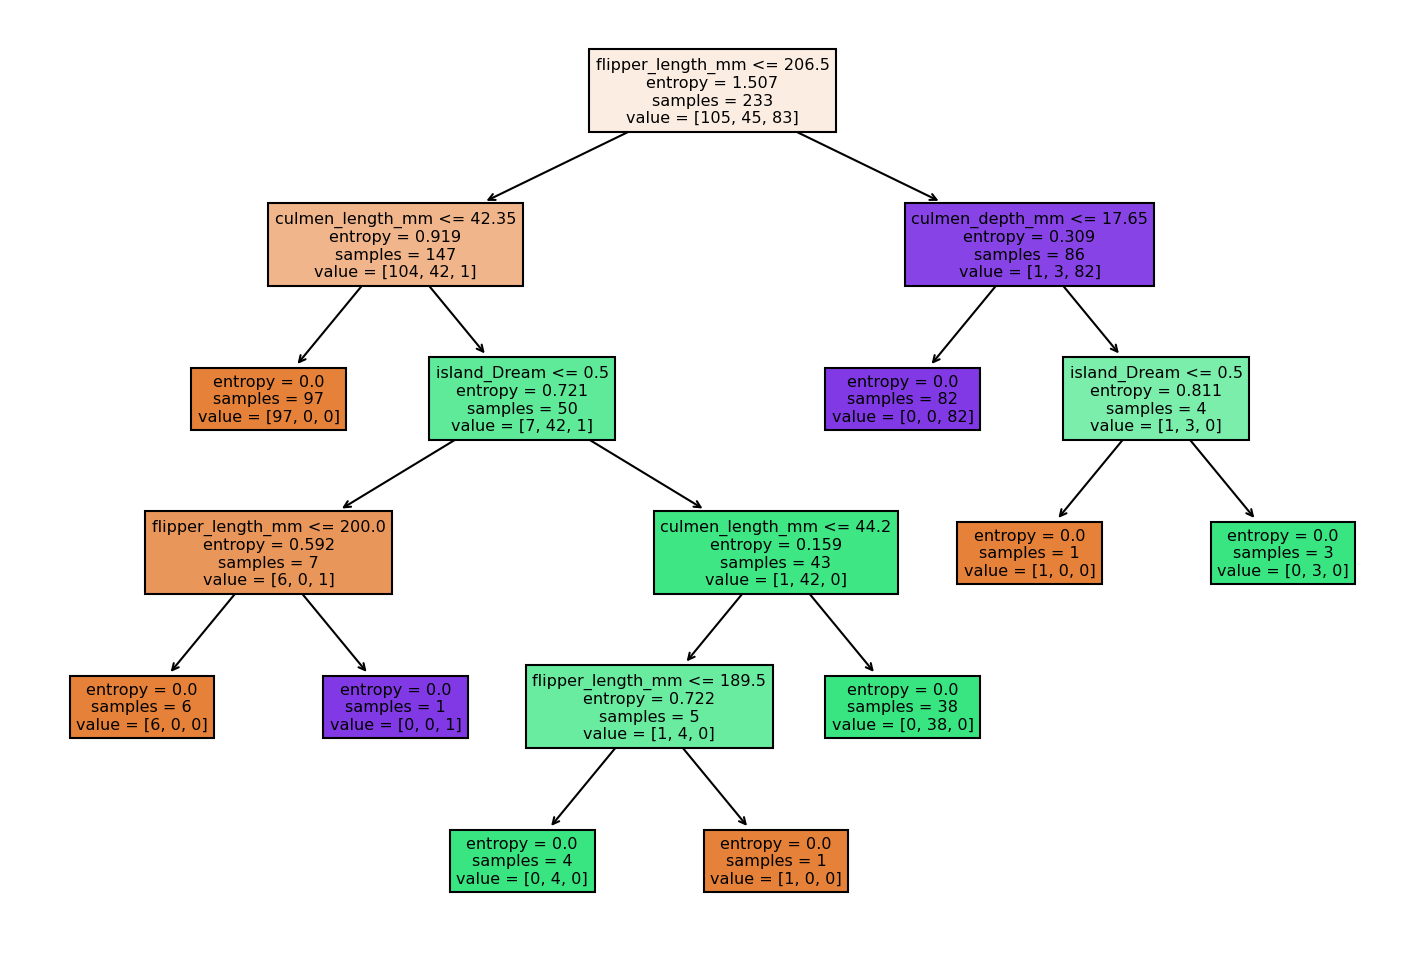

In [104]:
report_model(entropy_tree)

Je kan grid search met cross validation gebruiken om de beste hyperparameters te vinden!  Momenteel werkt het al goed met de default waarden dus hebben we dit niet gedaan...  Op een grotere dataset die moeilijker te classificeren is zal dit wel nuttig zijn.

Decision Trees zijn gevoelig aan overfitten, en er zijn veel ontwikkelingen die op deze basis verder werken zoals random forests of gradient boosting; dit zijn meer geavanceerde methoden die we gaan zien.  Daarom zal je in de praktijk niet vaak gewone decision trees zien.